# Homework 1: Exploring transfer

*Cognitive Modeling 2026–27 · 2 points · due in week 3*

In Unit 1 of the tutorial you saw that practice on one task can make another task faster, because the two tasks share parts of their operators. In this homework you measure this transfer yourself, explain it in terms of PRIMs, and do one experiment of your own. At the end you connect it to the dataset that we model in Homeworks 2 and 3.

**What you do**

1. Put your addition model of Homework 0 in this notebook, and write a second addition model that uses fingers (Part 1).
2. Measure the transfer from counting to both addition models (Part 2).
3. Explain the difference with the PRIMs that the models share (Part 3).
4. Do one experiment of your own (Part 4).
5. Think about the transfer in the Longman et al. (2024) experiment (Part 5).

All the Python code you need is already in the notebook. You write PRIMs operators, change numbers in the code cells, and answer the questions. Run the cells from top to bottom; if you change a model, run its cell again and then the cells below it.

**What you hand in:** this notebook, run from top to bottom, with your models and your answers in the answer cells, and a report of 1–2 pages (see the end of the notebook).

**Grading** (2 points): working models 0.5 · correct measurements 0.5 · explanation in terms of PRIMs 0.5 · own experiment 0.5.

**Files.** Keep this notebook in its folder: it uses `count.prims` and the helper module `cogmod.py` in the same folder. You don't have to read or change `cogmod.py`, but you are welcome to look at it.

In [1]:
from pyprims.notebook import Session, Dashboard
from cogmod import transfer_experiment, learning_curve, operator_prims, shared_prims
import pandas as pd

def show_model(path):
    """Print a model file."""
    print(open(path, encoding="utf-8").read())

## Part 1: two models of addition

### 1a. Addition by counting

Put the operators of your addition model from Homework 0 in the cell below (only the operators: the rest is already there), and run the cell. Then run the test cell below it: it runs one trial and prints the trace.

In [2]:
%%prims add --reset
// Add numbers by counting (your model from Homework 0)
// The script assumes that the final action is "answer"

define task add {
    initial-skills: (add)
    default-activation: 1.0
}

define skill add {
    // 1️⃣ INIT: put V1 in WM1, zero in WM2, ask for count fact about V1
  operator start-add {
    V1 <> nil          // there's a first addend
    WM1 = nil          // memory is empty (not started yet)
   ==>
    V1 -> WM1          // WM1 = first addend (current sum)
    zero -> WM2        // WM2 = current count (starts at zero)
    count-fact -> RT1  // retrieve: what comes after V1?
    V1 -> RT2
    V1 -> AC2
  }

// 2️⃣ HARVEST SUM: get next sum from WM1, ask for count fact about WM2
  operator update-sum {
    RT2 = WM1          // retrieved next-number matches current sum
    WM2 <> V2 //not correct answer
   ==>
    RT3 -> WM1         // WM1 = next sum (climb sum ladder) by one
    count-fact -> RT1  // retrieve: what comes after WM2 (the count)?
    WM2 -> RT2 // ask about the current count

  }
    // 3️⃣ HARVEST COUNT: get next count from WM2, check not done, ask for count fact about WM1
  operator update-count {
    RT2 = WM2          // retrieved next-count matches current count
    WM2 <> V2          // haven't reached the second addend yet
   ==>
    RT3 -> WM2         // WM2 = next count (climb count ladder)
    count-fact -> RT1  // retrieve: what comes after WM1 (the sum)?
    WM1 -> RT2
  }
    // 4️⃣ ANSWER: count reached V2 — say the sum in WM1
  operator give-answer {
    WM2 = V2           // count = second addend, we're done!
   ==>
    answer -> AC1      // the action the script waits for
    WM1 -> AC2         // say the sum
    nil -> G1          // clean up goal
  }
}

define facts {
    (cf0 count-fact  zero  one :activation 3.0)
    (cf1 count-fact  one  two :activation 3.0)
    (cf2 count-fact  two  three :activation 3.0)
    (cf3  count-fact  three  four :activation 3.0)
    (cf4  count-fact  four  five :activation 3.0)
    (cf5  count-fact  five  six :activation 3.0)
    (cf6  count-fact  six  seven :activation 3.0)
    (cf7  count-fact  seven  eight :activation 3.0)
    (cf8  count-fact  eight  nine :activation 3.0)
    (cf9  count-fact  nine  ten :activation 3.0)
}

define action say {
  latency: 0.3
  noise: 0.1
  distribution: uniform
  output: Saying
}

define script {
    digits = ["zero","one","two","three","four","five","six","seven","eight","nine","ten"]
    num1 = random(4) + 1
    num2 = random(4) + 1
    print("Adding",digits[num1],"and",digits[num2])
    screen(digits[num1],digits[num2])
    run-until-action("answer")
    ac = last-action()
    if (length(ac) > 1) {
        print("Answer", ac[1])
    }
    issue-reward()
    trial-end()
}

Loaded task 'add' into add (tasks: add)


In [3]:
add.run(1)
print(add.trace(1))

Adding two and four 
0.00  Starting new trial
0.00  *** Retrieved operator start-add with latency 0.001
1.86  *** Retrieved operator update-sum with latency 0.002
3.47  *** Retrieved operator update-count with latency 0.002
4.73  *** Retrieved operator update-sum with latency 0.001
6.34  *** Retrieved operator update-count with latency 0.001
7.95  *** Retrieved operator update-sum with latency 0.001
9.21  *** Retrieved operator update-count with latency 0.001
10.83  *** Retrieved operator update-sum with latency 0.000
12.09  *** Retrieved operator update-count with latency 0.001
14.05  *** Retrieved operator give-answer with latency 0.001
Answer six 
15.05  End of trial


### 1b. Addition with fingers

In the first model, the model keeps both counters in working memory: the sum (WM1) and how far it has counted (WM2). Children often use their fingers for the second counter. The model below does this: each time the model **says** a number, it sticks up a finger, and the script puts the number of fingers that are up in **V3**. The model can therefore compare V3 with the second number (V2) to know when to stop, instead of keeping the second counter in working memory.

So with "two plus three", the model starts with *two* in mind, and then says *three* (one finger up), *four* (two fingers), *five* (three fingers, which equals V2), and then answers *five*.

Write the operators for this model. You need four of them:

- an operator that starts: puts the first number in working memory and retrieves the count fact for it;
- an operator for the first count, when there are no fingers up yet (`V3 = nil`): it uses the retrieved count fact to update the number in working memory, retrieves the next count fact, and says the number;
- an operator for the other counts, as long as the number of fingers is not yet equal to the second number;
- an operator that gives the answer (`answer -> AC1`, the answer in AC2) and ends the goal (`nil -> G1`).

The model should transfer from the count model of Unit 1. Look at the count model's operators first:

In [4]:
show_model("count.prims")

// First example model: counting
// Adapted from the ACT-R tutorial by Niels Taatgen
//

define task count {
  initial-skills: (count) // In this example the task and the goal are the same
  default-activation: 1.0 // All chunks defined in this model receive a fixed baselevel activation of 1.0
  ol: t
  rt: -2.0
  lf: 0.2
  default-operator-self-assoc: 0.0
  egs: 0.05
  retrieval-reinforces: t
}


define skill count {
//  Start counting
  operator start-count {
   V1 <> nil  // There has to be an input with the starting number
   WM1 = nil  // Working Memory should be empty
  ==>
   V1 -> WM1 // Copy the start number to working memory
   count-fact -> RT1 // Start retrieving the next number
   V1 -> RT2
   say -> AC1 // Say the current number
   V1 -> AC2
   }

//    Iterate as long as count isn't done
  operator iterate {
    RT2 = WM1
    V2 <> WM1
   ==>
    RT3 -> WM1
    count-fact -> RT1
    RT3 -> RT2
    say -> AC1
    RT3 ->AC2
  }

//    Stop when reaching final number
  oper

In [5]:
%%prims fingers --reset
// Addition by counting, using the fingers to keep track of the second counter.
// Each "say" action sticks up a finger: the script then puts the number of
// fingers in V3. The final action must be "answer", followed by the answer.

define task add-fingers {
    initial-skills: (add-fingers)
    ol: t
    rt: -2.0
    lf: 0.2
    default-operator-self-assoc: 0.0
    egs: 0.05
    default-activation: 1.0
}

define skill add-fingers {
    // 1️⃣ START: put first addend in WM1, retrieve its count fact
  operator start-fingers {
    V1 <> nil          // there's a first addend
    WM1 = nil          // memory is empty
   ==>
    V1 -> WM1          // WM1 = first addend
    count-fact -> RT1  // retrieve: what comes after V1?
    V1 -> RT2
  }

  // 2️⃣ FIRST COUNT: no fingers up yet (V3 = nil)
  operator first-count {
    RT2 = WM1          // retrieved next-number matches current WM1
    V3 = nil           // no fingers up yet
   ==>
    RT3 -> WM1         // WM1 = next number
    count-fact -> RT1  // retrieve: what comes after this?
    RT3 -> RT2
    say -> AC1         // say it → a finger goes up!
    RT3 -> AC2
  }

  // 3️⃣ MORE COUNTS: keep going while fingers ≠ second addend
  operator count-more {
    RT2 = WM1          // same sanity check
    V3 <> V2           // fingers aren't equal to second addend yet
   ==>
    RT3 -> WM1         // WM1 = next number
    count-fact -> RT1  // retrieve next
    RT3 -> RT2
    say -> AC1         // say it → another finger goes up!
    RT3 -> AC2          // say new number
  }

  // 4️⃣ ANSWER: fingers = second addend → say WM1 and stop
  operator give-answer {
    V3 = V2            // fingers = second addend, done!
   ==>
    answer -> AC1      // say answer
    WM1 -> AC2         // say sum
    nil -> G1          // clean up goal buffeer
  }

}

define facts {
    (cf0 count-fact  zero  one)
    (cf1 count-fact  one  two)
    (cf2 count-fact  two  three)
    (cf3  count-fact  three  four)
    (cf4  count-fact  four  five)
    (cf5  count-fact  five  six)
    (cf6  count-fact  six  seven)
    (cf7  count-fact  seven  eight)
    (cf8  count-fact  eight  nine)
    (cf9  count-fact  nine  ten)
}

define script {
    digits = ["zero","one","two","three","four","five","six","seven","eight","nine","ten"]
    num1 = random(4) + 1
    num2 = random(4) + 1
    print("Adding",digits[num1],"and",digits[num2])
    screen(digits[num1],digits[num2])
    done = 0
    fingers = 0
    while (!done) {
        run-until-action()
        ac = last-action()
        if (ac[0] == "say") {
            fingers = fingers + 1
            screen(digits[num1],digits[num2],digits[fingers])
        }
        if (ac[0] == "answer") {
            done = 1
            print("Answer", ac[1])
        }
    }
    issue-reward()
    trial-end()
}

Loaded task 'add-fingers' into fingers (tasks: add-fingers)


In [6]:
fingers.run(1)
print(fingers.trace(3))

Adding three and four 
0.00  Starting new trial
0.00  *** Retrieved operator start-fingers with latency 0.001
0.00  Firing V1<>nil
0.05  Firing WM1=nil
0.35  Firing V1->WM1
0.65  Firing C1->RT1
0.95  Firing V1->RT2
1.25  Retrieving cf3 (latency = 0.058)
1.31  *** Retrieved operator first-count with latency 0.001
1.31  Firing WM1=RT2
1.36  Firing V3=nil
1.66  Firing RT3->WM1
1.96  Firing C1->RT1
2.26  Firing RT3->RT2
2.56  Firing C2->AC1
2.86  Firing RT3->AC2
3.16  Retrieving cf4 (latency = 0.050)
3.16  say-ing four-
       3.21  *** Retrieved operator start-fingers with latency 0.000
       3.21  Firing V1<>nil
       3.26  Firing WM1=nil
       3.56  Operator start-fingers1718 failed
3.56  *** Retrieved operator count-more with latency 0.000
3.56  Firing WM1=RT2
3.61  Firing V2<>V3
3.91  Firing RT3->WM1
4.21  Firing C1->RT1
4.51  Firing RT3->RT2
4.81  Firing C2->AC1
5.11  Firing RT3->AC2
5.41  Retrieving cf5 (latency = 0.055)
5.41  say-ing five-
       5.47  *** Retrieved operator fir

### If the model does not work

Your first version will probably not work. That is normal. Some tips:

- **Read the warnings.** A `NoOperatorWarning` means that the model got stuck: at some point, no operator had conditions that matched. A `ModelStuck` error means the same, inside the loop of the script.
- **Look at the trace in more detail.** `trace(2)` also shows retrievals and actions; `trace(3)` shows every PRIM, and which condition PRIM made an operator fail.
- **Step through a trial.** The cell below loads your model into a separate session `dbg` (so that the results of `fingers` are not affected) and carries out one operator at a time. After each step, look at the buffers: which operator should come next, and which of its conditions is not true?
- **Use the Dashboard**, as in the tutorial: it has buttons to step and run, and shows the trace, the buffers and declarative memory side by side.

After you change the model, run its `%%prims` cell again, and then the cells below it.

In [7]:
dbg = Session(seed=1)
dbg.load(fingers.source())     # a copy of your fingers model
dbg.step_operator()            # run until the first operator has been carried out
dbg.buffers()

Operator
  start-fingers
  Conditions: V1<>nil WM1=nil
  Actions: V1->WM1 C1->RT1 V1->RT2
  Constants:
  C1 count-fact
Input
  V1 two
  V2 one
Goal
  G0 currentGoalChunk0
  G1 add-fingers
Retrieval request
  RT0 retrievalR11
  RT1 count-fact
  RT2 two
New harvest
  RT0 cf2
  RT1 count-fact
  RT2 two
  RT3 three
New imaginal
  WM0 imaginal10
  WM1 two

In [8]:
dbg.step_operator()            # the next operator (run this cell a few times)
print(dbg.trace(3)[-1500:])    # the end of the detailed trace
dbg.buffers()

Adding two and one 
0.00  Starting new trial
0.00  *** Retrieved operator start-fingers with latency 0.002
0.00  Firing V1<>nil
0.05  Firing WM1=nil
0.35  Firing V1->WM1
0.65  Firing C1->RT1
0.95  Firing V1->RT2
1.25  Retrieving cf2 (latency = 0.050)
1.30  *** Retrieved operator first-count with latency 0.001
1.30  Firing WM1=RT2
1.35  Firing V3=nil
1.65  Firing RT3->WM1
1.95  Firing C1->RT1
2.25  Firing RT3->RT2
2.55  Firing C2->AC1
2.85  Firing RT3->AC2
3.15  Retrieving cf3 (latency = 0.036)
3.15  say-ing three-


Operator
  first-count
  Conditions: WM1=RT2 V3=nil
  Actions: RT3->WM1 C1->RT1 RT3->RT2 C2->AC1 RT3->AC2
  Constants:
  C1 count-fact
  C2 say
Input
  V1 two
  V2 one
Action
  AC1 say
  AC2 three
New input
  V1 two
  V2 one
  V3 one
Goal
  G0 currentGoalChunk0
  G1 add-fingers
Retrieval harvest
  RT0 cf2
  RT1 count-fact
  RT2 two
  RT3 three
Retrieval request
  RT0 retrievalR14
  RT1 count-fact
  RT2 three
New harvest
  RT0 cf3
  RT1 count-fact
  RT2 three
  RT3 four
Imaginal
  WM0 imaginal10
  WM1 three

In [9]:
# The Dashboard: Step, Step op, Run, and the trace, buffers and declarative memory
Dashboard(dbg)

Check that both models give the right answer for a few trials (the trace shows the numbers that are added, and the answer). Then check that they learn: run 50 trials and plot the results.

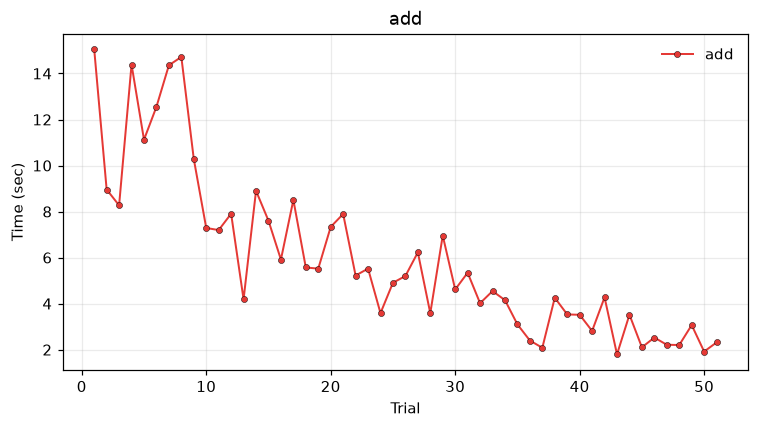

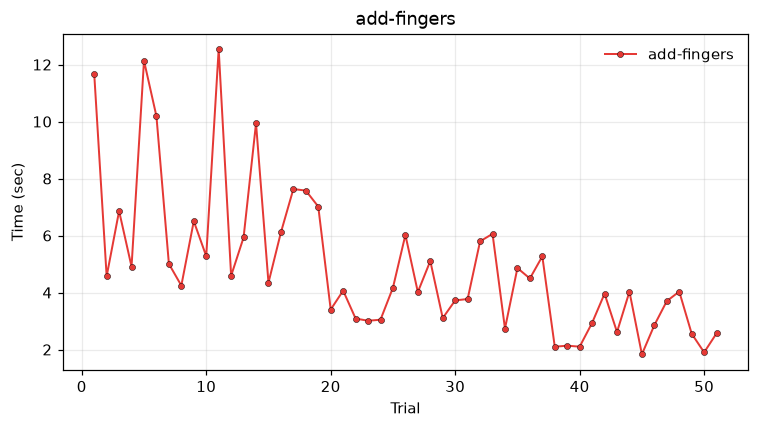

In [10]:
add.run(50)
fingers.run(50)
add.plot_results(title="add");
fingers.plot_results(title="add-fingers");

## Part 2: measuring transfer

The function `transfer_experiment` makes a fresh model for each of a number of *runs* (a "run" is one simulated participant). If you give it a `train` model, each model first does `n_train` trials of that model, and then `n_test` trials of the `test` model. It returns the data of the test trials as a table: one row per trial, with the trial time in the column `result`.

Because the model is stochastic, the results differ between runs; we therefore average over 20 runs. `learning_curve` plots the mean trial time per block of trials, with a band of ±1 standard error, and returns the means as a table.

Run the cell below. It takes about half a minute.

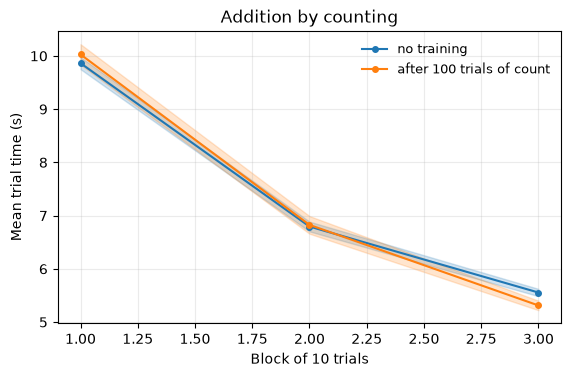

block,1,2,3
no training,9.86,6.80,5.56
after 100 trials of count,10.03,6.83,5.31


In [11]:
results_add = [
    transfer_experiment(add, runs=40, n_test=30),
    transfer_experiment(add, train="count.prims", n_train=100, runs=20, n_test=30),
]
results_fingers = [
    transfer_experiment(fingers, runs=40, n_test=30),
    transfer_experiment(fingers, train="count.prims", n_train=100, runs=20, n_test=30),
]
learning_curve(results_add, block=10, title="Addition by counting")

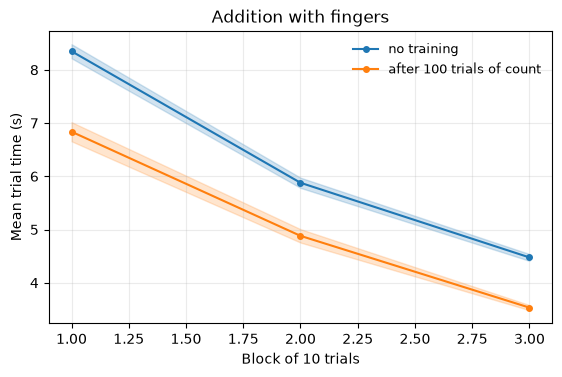

block,1,2,3
no training,8.35,5.88,4.48
after 100 trials of count,6.84,4.88,3.53


In [12]:
learning_curve(results_fingers, block=10, title="Addition with fingers")

**Question 2.1.** For which of the two models does counting practice help? How large is the difference in the first block of 10 trials (in seconds, and as a percentage)? Does the difference stay the same in later blocks? (If you are not sure whether a difference is real or noise, rerun with more runs, for example `runs=40`.)

My answer: The counting practice helps more for the model that uses addition with fingers. The difference of means between 'no training' and 'after 100 trials of count' in the first block is 1.79s (-5.9%) compared to the model with WM addition with the difference of 0.15s (+0.99%). The difference does not stay completely same but similar (the difference is smaller in other blocks).

## Part 3: why is there transfer?

In PRIMs, each operator is carried out as a sequence of PRIMs: first the conditions, then the actions. `operator_prims` shows these sequences. Constants (such as `count-fact` or `say`) are written as C1, C2, ... in the order in which they appear in the operator: this is how PRIMs represents them, so `say -> AC1` in one operator and `answer -> AC1` in another are the same PRIM `C1->AC1`, if the constant is the first one in both operators.

In [13]:
pd.set_option("display.max_colwidth", 120)
operator_prims("count.prims")

,task,operator,conditions,actions
0,count,start-count,V1<>nil ; WM1=nil,V1->WM1 ; C1->RT1 ; V1->RT2 ; C2->AC1 ; V1->AC2
1,count,iterate,WM1=RT2 ; V2<>WM1,RT3->WM1 ; C1->RT1 ; RT3->RT2 ; C2->AC1 ; RT3->AC2
2,count,final,V2=WM1,C1->AC1 ; C2->AC2 ; nil->G1


In [14]:
operator_prims(fingers)

,task,operator,conditions,actions
0,add-fingers,start-fingers,V1<>nil ; WM1=nil,V1->WM1 ; C1->RT1 ; V1->RT2
1,add-fingers,first-count,WM1=RT2 ; V3=nil,RT3->WM1 ; C1->RT1 ; RT3->RT2 ; C2->AC1 ; RT3->AC2
2,add-fingers,count-more,WM1=RT2 ; V2<>V3,RT3->WM1 ; C1->RT1 ; RT3->RT2 ; C2->AC1 ; RT3->AC2
3,add-fingers,give-answer,V2=V3,C1->AC1 ; WM1->AC2 ; nil->G1


With practice, production compilation combines PRIMs that are carried out after each other into larger productions. These productions are not specific to an operator. A production is used whenever **what remains to be done** of the operator that is being carried out is exactly what the production was learned for. So a production that is learned for the end of one operator can be used for another operator, even of another task, if the two operators **end with the same sequence of PRIMs**.

`shared_prims` lists, for each pair of operators of two models, the longest sequence of PRIMs at the end that they have in common (by default only sequences of at least 2 PRIMs):

In [15]:
shared_prims("count.prims", add)

No shared sequences of 2 or more PRIMs.


In [16]:
shared_prims("count.prims", fingers)

,operator in count,operator in add-fingers,shared PRIMs,shared sequence,whole operator
0,iterate,first-count,5,RT3->WM1 ; C1->RT1 ; RT3->RT2 ; C2->AC1 ; RT3->AC2,False
1,iterate,count-more,5,RT3->WM1 ; C1->RT1 ; RT3->RT2 ; C2->AC1 ; RT3->AC2,False


You can also see this in the PRIMs graph of Unit 1: load both models in one session, and plot the graph at level 2. PRIMs that are used by operators of both tasks have a yellow halo.

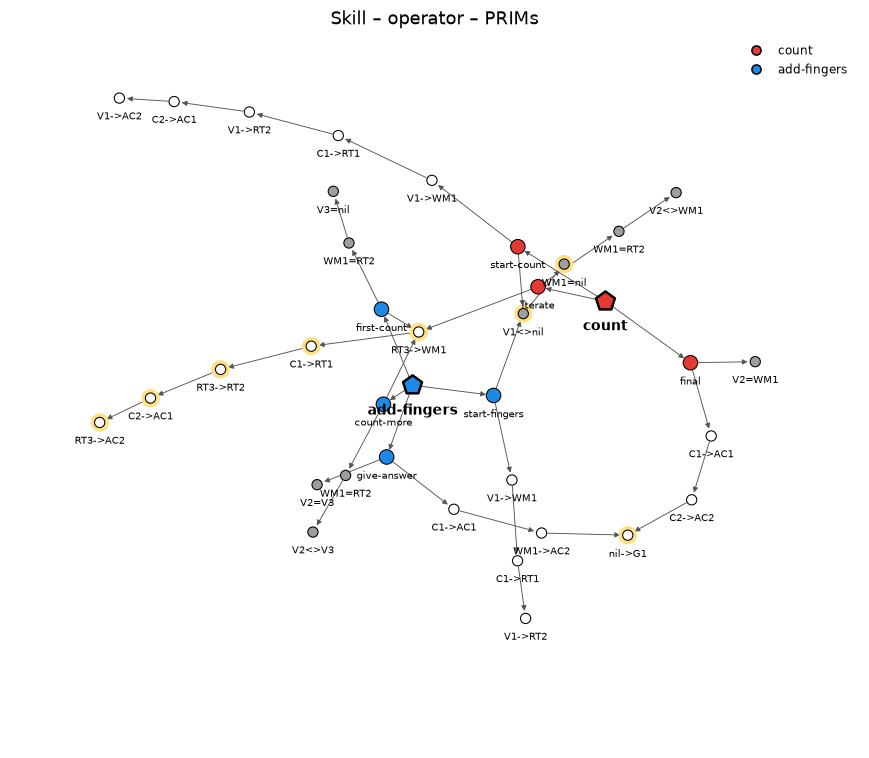

In [22]:
both = Session(seed=1)
both.load("count.prims")
both.load(fingers.source())
#both.load(add.source())
both.plot_graph(2);

**Question 3.1.** Explain the result of Part 2 with these tables. Which operators of count and the addition models share sequences of PRIMs, and which do not? Why does that lead to transfer for one model and not (or less) for the other? Your answer should be at the level of PRIMs and productions, not of "the tasks are similar".

**Question 3.2.** The addition-by-counting model also counts, so why does it not share the count model's sequences? (Look at the order of the actions, and at what the model keeps in WM2.)

Question 3.1: In the finger-addition model there are 2 operators that share sequences of PRIMs with the count model. For the finger-addition model, the operators are first-count and count-more that are identical to iterate in count model. The operator is not fully identical but they have 5 shared PRIMs in the sequence: RT3->WM1 ; C1->RT1 ; RT3->RT2 ; C2->AC1 ; RT3->AC2. For the addition model from assignment #0, there are no shared sequences of 2 or more PRIMS. The reason why the shared PRIMS lead to transfer for one model and not the other is because when you run the first model, there is no previous model to learn from (or to make it faster). When you apply the second model, the transfer begins if they have shared PRIMs. Since the model has already practiced some operators in the past, they can run it faster in multiple steps at once instead of one by one. Just like how you can apply your skills of using measurements in the kitchen to using measurements in the lab.


Question 3.2:The reason why the addition-by-counting model does not share the count model's sequences is because it uses WM2 to keep track of how many times we count instead. Additionally, we don't use say in the addition-by-counting model.

## Part 4: an experiment of your own

Choose **one** of the experiments below (or think of another one and check it with the instructor). For each, first write down what you **predict**, then run the experiment, and then explain the result. Your experiment can use the same functions as Part 2.

**A. Order of the actions.** Make a copy of your fingers model in which the actions of the counting operators are in a different order (but the model still works). Predict what happens to the transfer from counting, and use `shared_prims` to check your prediction before you run `transfer_experiment`. You can also try the opposite: change your addition-by-counting model so that it shares more with counting.

**B. Amount of training.** How does the amount of transfer depend on the amount of counting practice? Vary `n_train` (for example 0, 10, 25, 50, 100, 200) and plot the mean time of the first 10 test trials against `n_train`. Is there a point where more practice does not help any more, and why?

**C. Far transfer (more work).** In Unit 3 of the tutorial, practice on task switching transfers to the Stroop task, even though the tasks look very different. Measure this transfer with `transfer_experiment`, using the models of Unit 3, and explain it with `shared_prims`.

Below is a cell that you can use as a starting point.

In [37]:
%%prims fingers2 --reset
// For experiment A: copy your operators of the fingers model, and change the order of the actions
// Addition by counting, using the fingers to keep track of the second counter.
// Each "say" action sticks up a finger: the script then puts the number of
// fingers in V3. The final action must be "answer", followed by the answer.

define task add-fingers2 {
    initial-skills: (add-fingers2)
    ol: t
    rt: -2.0
    lf: 0.2
    default-operator-self-assoc: 0.0
    egs: 0.05
    default-activation: 1.0
}

define skill add-fingers2 {
    // change the  order so it'slighlty different from the first addition-fingers model

// 1️⃣ START: put first addend in WM1, retrieve its count fact
  operator start-fingers {
    WM1 = nil          // memory is empty
    V1 <> nil          // there's a first addend
   ==>
    count-fact -> RT1  // retrieve: what comes after V1?
    V1 -> RT2
    V1 -> WM1          // WM1 = first addend
  }

  // 2️⃣ FIRST COUNT: no fingers up yet (V3 = nil)
  operator first-count {
    RT2 = WM1          // retrieved next-number matches current WM1
    V3 = nil           // no fingers up yet
   ==>
    RT3 -> RT2
    count-fact -> RT1  // retrieve: what comes after this?
    RT3 -> WM1         // WM1 = next number
    say -> AC1         // say it → a finger goes up!
    RT3 -> AC2
  }

  // 3️⃣ MORE COUNTS: keep going while fingers ≠ second addend
  operator count-more {
    V3 <> V2           // fingers aren't equal to second addend yet
    RT2 = WM1          // same sanity check
   ==>
    count-fact -> RT1  // retrieve next
    RT3 -> RT2
    RT3 -> WM1         // WM1 = next number
    say -> AC1         // say it → another finger goes up!
    RT3 -> AC2          // say new number
  }

  // 4️⃣ ANSWER: fingers = second addend → say WM1 and stop
  operator give-answer {
    V3 = V2            // fingers = second addend, done!
   ==>
    answer -> AC1      // say answer
    WM1 -> AC2         // say sum
    nil -> G1          // clean up goal buffeer
  }
}

define facts {
    (cf0 count-fact  zero  one)
    (cf1 count-fact  one  two)
    (cf2 count-fact  two  three)
    (cf3  count-fact  three  four)
    (cf4  count-fact  four  five)
    (cf5  count-fact  five  six)
    (cf6  count-fact  six  seven)
    (cf7  count-fact  seven  eight)
    (cf8  count-fact  eight  nine)
    (cf9  count-fact  nine  ten)
}

define script {
    digits = ["zero","one","two","three","four","five","six","seven","eight","nine","ten"]
    num1 = random(4) + 1
    num2 = random(4) + 1
    print("Adding",digits[num1],"and",digits[num2])
    screen(digits[num1],digits[num2])
    done = 0
    fingers = 0
    while (!done) {
        run-until-action()
        ac = last-action()
        if (ac[0] == "say") {
            fingers = fingers + 1
            screen(digits[num1],digits[num2],digits[fingers])
        }
        if (ac[0] == "answer") {
            done = 1
            print("Answer", ac[1])
        }
    }
    issue-reward()
    trial-end()
}

Loaded task 'add-fingers2' into fingers2 (tasks: add-fingers2)


In [40]:
fingers2.run(1)
print(fingers2.trace(2))

Adding three and four 
14.98  Starting new trial
14.99  *** Retrieved operator start-fingers with latency 0.002
16.24  Retrieving cf3 (latency = 0.039)
16.28  *** Retrieved operator first-count with latency 0.002
18.13  Retrieving cf4 (latency = 0.100)
18.13  say-ing four-
18.23  *** Retrieved operator count-more with latency 0.002
20.08  Retrieving cf5 (latency = 0.042)
20.08  say-ing five-
20.48  *** Retrieved operator count-more with latency 0.003
22.33  Retrieving cf6 (latency = 0.064)
22.33  say-ing six-
22.75  *** Retrieved operator count-more with latency 0.002
24.60  Retrieving cf7 (latency = 0.039)
24.60  say-ing seven-
24.65  *** Retrieved operator give-answer with latency 0.001
Answer seven 
25.60  answer-ing seven-
25.65  End of trial


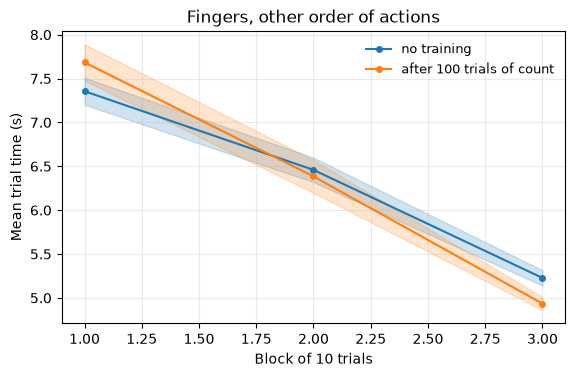

<Axes: xlabel='n_train'>

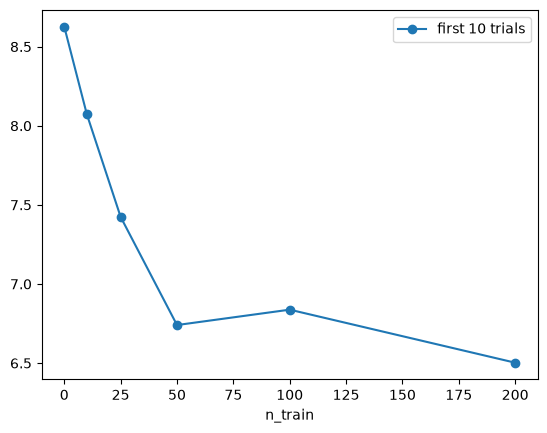

In [41]:
# Experiment A, for example:
shared_prims("count.prims", fingers2)
results_a = [transfer_experiment(fingers2, runs=20, n_test=30),
             transfer_experiment(fingers2, train="count.prims", n_train=100, runs=20, n_test=30)]
learning_curve(results_a, block=10, title="Fingers, other order of actions")

# Experiment B, for example:
rows = []
for n in [0, 10, 25, 50, 100, 200]:
    d = transfer_experiment(fingers, train="count.prims" if n > 0 else None, n_train=n, runs=20, n_test=10)
    rows.append({"n_train": n, "first 10 trials": d.result.mean()})
pd.DataFrame(rows).plot(x="n_train", y="first 10 trials", marker="o")

My prediction:


A: I think the order would not matter when it comes to training the model and the process would it be similar as the first time running the finger addition model.


Results A: 

B: I think the amount of practice matters until a certain point. When a person practices one skill a lot, they become proficient. With more practice, they can become professionals with the RT close to sound maybe but not faster than the light. I think the comparison is also for the model, at some point, the model cannot get faster. I assume it will stagnate around run 50?

## Part 5: transfer in the Longman et al. (2024) experiment

In Homeworks 2 and 3 we model Experiment 2 of Longman, Milton & Wills (2024). Read the introduction and the method of Experiment 2 (the paper is on the course website). In short:

- The **test task** (the last block, for all participants) is dot-pattern classification. On each trial participants see a pattern of dots that is a distorted version of one of two category templates (for example a triangle or a cross), and type the two-digit code of its category on the numeric keypad (for example 3–7). They learn the codes from an instruction screen and from feedback.
- Before the test, participants do five training blocks of 48 trials, each with a new task. The training tasks differ between the eight groups. They share one, two, three or none of the three *components* of the test task: the **perceptual** component (the same kind of dot-pattern stimuli), the **categorization** component (classifying stimuli by comparing them with a category template) and the **motoric** component (typing two-digit codes on the numeric keypad). For example, the motoric group types codes that are shown on the screen; the perceptual group sees dot patterns to the left or right of the screen and presses F or J; the control group judges whether sums are true or false with F or J.

**Question 5.1.** Think of the test task as a PRIMs model. Which operators would it need? Which of those could be shared with operators of the perceptual, the categorization and the motoric training tasks? On the basis of your answer, predict for each of these three groups whether it is faster and/or makes fewer errors in the test task than the control group, and in which part of the response (the first digit or the second).

You don't need to write a model: a list of operators in words is enough. We come back to your predictions in Homework 3.

## The report

Write a report of 1–2 pages (PDF) with:

1. **Models** (short): how your fingers model works, in a few sentences.
2. **Results:** the two learning-curve plots of Part 2 and the plot(s) of your experiment, with a sentence on each about what it shows.
3. **Explanation:** your answers to Questions 3.1 and 3.2, and the explanation of your experiment, at the level of PRIMs and productions.
4. **The dataset:** your answer to Question 5.1.

Hand in the report together with this notebook.